In [1]:
import scanpy as sc
import matplotlib.pyplot as plt
import sklearn.metrics as metrics
import os

In [2]:
os.chdir('/data/lxj/CroSP')

## D7

In [3]:
data_name = 'D7'
dataset_name = 'ChickenHeart'

In [4]:
input_dir = os.path.join('./Results', 'Final', 'ChickenHeart_fixed_best_20260908', data_name)
output_dir = os.path.join('./Results', 'Figure', dataset_name, 'Tutorial', 'fixed_best_20260908', data_name)
os.makedirs(output_dir, exist_ok=True)

In [5]:
adata = sc.read(os.path.join(input_dir, data_name + '_CroSP_best.h5ad'))
adata

AnnData object with n_obs × n_vars = 535 × 24356
    obs: 'in_tissue', 'array_row', 'array_col', 'imagecol', 'imagerow', 'raw_total_counts', 'raw_n_genes_by_counts', 'CroSP_cluster', 'region'
    var: 'gene_ids', 'feature_types', 'genome'
    uns: 'CroSP_run', 'spatial'
    obsm: 'CroSP', 'CroSP_full', 'spatial'

In [6]:
obs_df = adata.obs[['CroSP_cluster', 'region']].dropna()
ARI = metrics.adjusted_rand_score(obs_df['CroSP_cluster'], obs_df['region'])
AMI = metrics.adjusted_mutual_info_score(obs_df['CroSP_cluster'], obs_df['region'])
NMI = metrics.normalized_mutual_info_score(obs_df['CroSP_cluster'], obs_df['region'])
HC = metrics.homogeneity_score(obs_df['region'], obs_df['CroSP_cluster'])
print('ARI = %.4f' % ARI)
print('AMI = %.4f' % AMI)
print('NMI = %.4f' % NMI)
print('HC = %.4f' % HC)

ARI = 0.4861
AMI = 0.5551
NMI = 0.5634
HC = 0.5589


/home/lxj/miniconda3/envs/CroSP/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


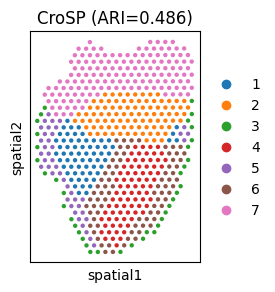

In [7]:
plt.rcParams['figure.figsize'] = (3, 3)
sc.pl.embedding(adata, basis='spatial', color='CroSP_cluster',
                title='CroSP (ARI=%.3f)' % ARI, s=40, show=False)
plt.gca().set_aspect('equal')
plt.gca().invert_yaxis()
plt.savefig(os.path.join(output_dir, 'pred_domain.svg'), bbox_inches='tight', dpi=300)

/home/lxj/miniconda3/envs/CroSP/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


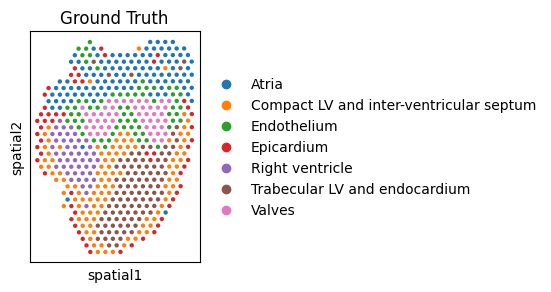

In [8]:
plt.rcParams['figure.figsize'] = (3, 3)
sc.pl.embedding(adata, basis='spatial', color='region', title='Ground Truth', s=40, show=False)
plt.gca().set_aspect('equal')
plt.gca().invert_yaxis()
plt.savefig(os.path.join(output_dir, 'true_domain.svg'), bbox_inches='tight', dpi=300)

In [9]:
sc.pp.neighbors(adata, use_rep='CroSP')
sc.tl.umap(adata)

/home/lxj/miniconda3/envs/CroSP/lib/python3.9/site-packages/umap/distances.py:1063: NumbaDeprecationWarning: The 'nopython' keyword argument was not supplied to the 'numba.jit' decorator. The implicit default value for this argument is currently False, but it will be changed to True in Numba 0.59.0. See https://numba.readthedocs.io/en/stable/reference/deprecation.html#deprecation-of-object-mode-fall-back-behaviour-when-using-jit for details.
  @numba.jit()
/home/lxj/miniconda3/envs/CroSP/lib/python3.9/site-packages/umap/distances.py:1071: NumbaDeprecationWarning: The 'nopython' keyword argument was not supplied to the 'numba.jit' decorator. The implicit default value for this argument is currently False, but it will be changed to True in Numba 0.59.0. See https://numba.readthedocs.io/en/stable/reference/deprecation.html#deprecation-of-object-mode-fall-back-behaviour-when-using-jit for details.
  @numba.jit()
/home/lxj/miniconda3/envs/CroSP/lib/python3.9/site-packages/umap/distances.py:

/home/lxj/miniconda3/envs/CroSP/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(
/home/lxj/miniconda3/envs/CroSP/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


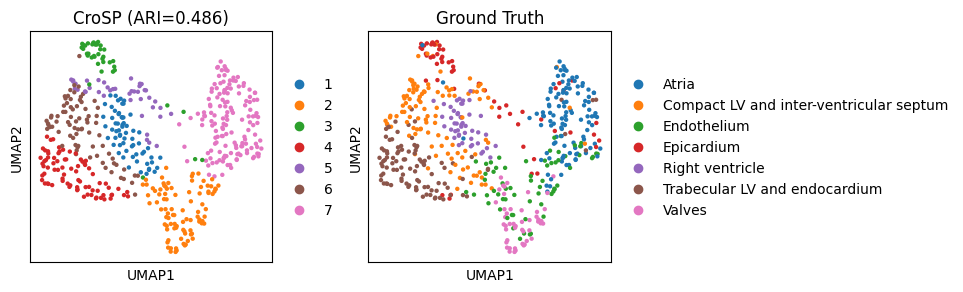

In [10]:
plt.rcParams['figure.figsize'] = (3, 3)
sc.pl.umap(adata, color=['CroSP_cluster', 'region'],
           title=['CroSP (ARI=%.3f)' % ARI, 'Ground Truth'], s=40, show=False)
plt.savefig(os.path.join(output_dir, 'umap_domain.svg'), bbox_inches='tight', dpi=300)

## D14

In [11]:
data_name = 'D14'
dataset_name = 'ChickenHeart'

In [12]:
input_dir = os.path.join('./Results', 'Final', 'ChickenHeart_fixed_best_20260908', data_name)
output_dir = os.path.join('./Results', 'Figure', dataset_name, 'Tutorial', 'fixed_best_20260908', data_name)
os.makedirs(output_dir, exist_ok=True)

In [13]:
adata = sc.read(os.path.join(input_dir, data_name + '_CroSP_best.h5ad'))
adata

AnnData object with n_obs × n_vars = 1967 × 24356
    obs: 'in_tissue', 'array_row', 'array_col', 'imagecol', 'imagerow', 'raw_total_counts', 'raw_n_genes_by_counts', 'CroSP_cluster', 'region'
    var: 'gene_ids', 'feature_types', 'genome'
    uns: 'CroSP_run', 'spatial'
    obsm: 'CroSP', 'CroSP_full', 'spatial'

In [14]:
obs_df = adata.obs[['CroSP_cluster', 'region']].dropna()
ARI = metrics.adjusted_rand_score(obs_df['CroSP_cluster'], obs_df['region'])
AMI = metrics.adjusted_mutual_info_score(obs_df['CroSP_cluster'], obs_df['region'])
NMI = metrics.normalized_mutual_info_score(obs_df['CroSP_cluster'], obs_df['region'])
HC = metrics.homogeneity_score(obs_df['region'], obs_df['CroSP_cluster'])
print('ARI = %.4f' % ARI)
print('AMI = %.4f' % AMI)
print('NMI = %.4f' % NMI)
print('HC = %.4f' % HC)

ARI = 0.6306
AMI = 0.5789
NMI = 0.5806
HC = 0.5710


/home/lxj/miniconda3/envs/CroSP/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


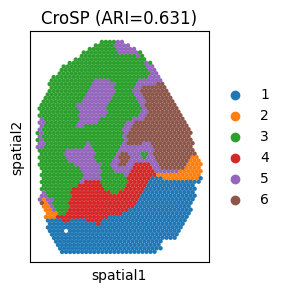

In [15]:
plt.rcParams['figure.figsize'] = (3, 3)
sc.pl.embedding(adata, basis='spatial', color='CroSP_cluster',
                title='CroSP (ARI=%.3f)' % ARI, s=40, show=False)
plt.gca().set_aspect('equal')
plt.gca().invert_yaxis()
plt.savefig(os.path.join(output_dir, 'pred_domain.svg'), bbox_inches='tight', dpi=300)

/home/lxj/miniconda3/envs/CroSP/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


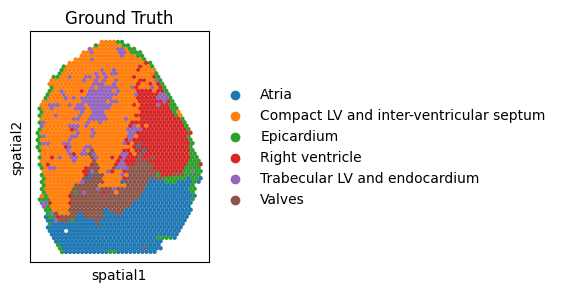

In [16]:
plt.rcParams['figure.figsize'] = (3, 3)
sc.pl.embedding(adata, basis='spatial', color='region', title='Ground Truth', s=40, show=False)
plt.gca().set_aspect('equal')
plt.gca().invert_yaxis()
plt.savefig(os.path.join(output_dir, 'true_domain.svg'), bbox_inches='tight', dpi=300)

In [17]:
sc.pp.neighbors(adata, use_rep='CroSP')
sc.tl.umap(adata)

/home/lxj/miniconda3/envs/CroSP/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(
/home/lxj/miniconda3/envs/CroSP/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


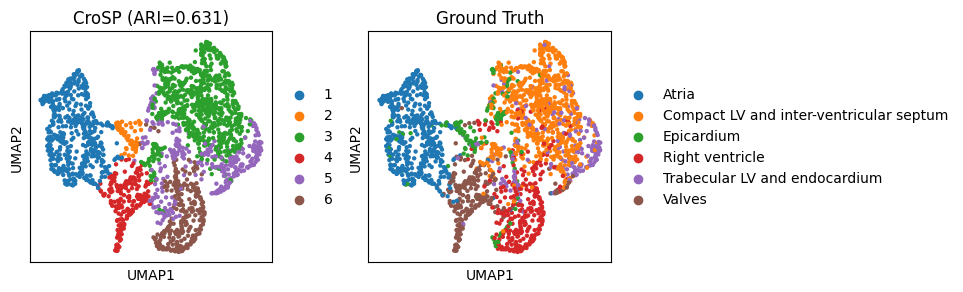

In [18]:
plt.rcParams['figure.figsize'] = (3, 3)
sc.pl.umap(adata, color=['CroSP_cluster', 'region'],
           title=['CroSP (ARI=%.3f)' % ARI, 'Ground Truth'], s=40, show=False)
plt.savefig(os.path.join(output_dir, 'umap_domain.svg'), bbox_inches='tight', dpi=300)